# Lezione 07 — Scheda Caso TakeHome
## Pricing Monte Carlo di una call asiatica sull'EURO STOXX 50 con tasso di interesse stocastico

**Contesto:** Valutazione di una call asiatica OTC a media aritmetica su indice azionario, con tasso nominale stocastico.
**Data di riferimento:** 27 luglio 2026

### Domanda Quantitativa
Qual è il valore corrente della call asiatica sull'EURO STOXX 50, stimato mediante simulazione Monte Carlo, quando il livello dell'indice e il tasso nominale evolvono congiuntamente in modo stocastico sotto la misura risk-neutral $\mathbb Q$?

### Variabile Finale e Informazione Disponibile
La variabile finale è il prezzo Monte Carlo della call asiatica $\widehat V_M$, stimato a partire dai payoff attualizzati ottenuti nelle singole repliche Monte Carlo. 
Le informazioni disponibili includono i dati di mercato al 27/07/2026, le proxy di mercato per volatilità e dividendi, i parametri del modello stocastico (dinamica CIR per il tasso e geometrica per il sottostante), e le specifiche del contratto (scadenza a 1 anno, 12 fixing mensili).

---

### Quantità da stimare o calcolare
1. Media e deviazione standard simulate di $S_T$ e $r_T$.
2. Media e deviazione standard simulate di $A_T$.
3. Probabilità simulata di esercizio sotto $\mathbb Q$, ovvero $\widehat{\mathbb Q}(A_T>K)$.
4. Valore medio del payoff non attualizzato $H_T$.
5. Prezzo Monte Carlo della call asiatica $\widehat V_M$.
6. Errore standard Monte Carlo e intervallo di confidenza al $95\%$.

---

### Output Richiesti

#### Tabelle
1. **Tabella dei parametri del caso**, distinguendo dati osservati, proxy di mercato, specifiche contrattuali e parametri didattici.
2. **Tabella delle statistiche dei fattori e della media asiatica**, contenente media e deviazione standard di $S_T$, $r_T$, $A_T$.
3. **Tabella di sintesi del payoff e del pricing**, contenente almeno:
   - probabilità simulata di esercizio;
   - payoff medio;
   - prezzo Monte Carlo;
   - errore standard Monte Carlo;
   - intervallo di confidenza al $95\%$.
4. **Tabella di diagnostica Monte Carlo** per $M=1\,000,\;5\,000,\;10\,000,\;50\,000$, riportando almeno prezzo stimato ed errore standard.

#### Grafici
1. Alcune traiettorie simulate dell'EURO STOXX 50, $S_t$.
2. Alcune traiettorie simulate del tasso nominale $r_t$.
3. Distribuzione simulata di $A_T$, con evidenza dello strike $K$.
4. Distribuzione dei valori attualizzati $V^{(k)}$.
5. Grafico di convergenza della stima Monte Carlo al crescere di $M$.

---

### Controlli Richiesti

Il notebook deve verificare esplicitamente che:
1. La correlazione empirica degli shock simulati sia coerente con $\rho=-0,25$.
2. Il sottostante soddisfi $S_{t_j}^{(k)}>0$ per ogni replica e data.
3. Eventuali valori negativi di $r_t$ prodotti dalla discretizzazione siano rilevati e documentati senza azzerare sistematicamente il valore aggiornato.
4. Per ogni replica valga $\min_h S_{\tau_h}^{(k)}\leq A_T^{(k)} \leq\max_h S_{\tau_h}^{(k)}$.
5. Il payoff soddisfi $H_T^{(k)}\geq0$ e sia nullo quando $A_T^{(k)}\leq K$.
6. L'integrale del tasso sia costruito utilizzando $r_{t_0}^{(k)},\ldots,r_{t_{N-1}}^{(k)}$ appartenenti alla stessa replica e il fattore di sconto soddisfi $\widehat D^{(k)}(0,T)>0$.
7. Il valore attualizzato soddisfi $V^{(k)}= \widehat D^{(k)}(0,T)H_T^{(k)}$.
8. L'errore standard Monte Carlo diminuisca al crescere di $M$ in modo compatibile con $O(M^{-1/2})$.
9. Il prezzo sia sufficientemente stabile rispetto a una griglia temporale più fine.
10. I risultati principali siano riproducibili mediante il seed assegnato.

---

> **NOTA IMPORTANTE:** La presente Scheda Caso costituisce la specifica vincolante del lavoro e non deve essere modificata in alcun modo durante lo svolgimento dell'applicazione.

# Flusso logico-teorico risolutivo

**Feedback sulla proposta dello studente:**
La tua sequenza logica è ben impostata e centra i passaggi principali. Tuttavia, ci sono alcune integrazioni e correzioni necessarie per allinearla perfettamente alla Scheda Caso:
- **Correzione al tuo Punto 6:** Hai indicato "media dei valori finali del sottostante", ma la call asiatica richiede la media dei livelli osservati nelle **12 date di fixing mensili** ($S_{\tau_h}$), non dei soli valori finali.
- **Integrazione sui tassi (Punto 3):** È fondamentale prevedere il controllo teorico della *Condizione di Feller* a priori, e gestire esplicitamente (e documentare) la presenza di tassi negativi applicando l'operatore $\max(r,0)$ sotto radice come prescritto dalla convenzione numerica.
- **Integrazione sugli shock (Punto 5):** Occorre esplicitare il meccanismo di correlazione degli shock browniani a partire da due normali standard indipendenti.

Ecco il flusso logico-teorico riordinato e completato, strutturato secondo le richieste:

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | **Inizializzazione e verifica teorica** | $2\kappa_r\theta_r \geq \sigma_r^2$ (Condizione di Feller) | Definizione dei parametri per EURO STOXX 50 e tasso CIR, verifica della condizione di non negatività teorica del CIR. | Tabella 1 (Parametri del caso). |
| 2 | **Generazione degli shock correlati** | $Z_{S,j}^{(k)}= Z_{1,j}^{(k)}$<br>$Z_{r,j}^{(k)}= \rho Z_{1,j}^{(k)} + \sqrt{1-\rho^2}\, Z_{2,j}^{(k)}$ | Costruzione della dipendenza tra la dinamica dell'indice e quella del tasso di interesse tramite scomposizione lineare. | Controllo 1 (Correlazione empirica coerente con $\rho=-0,25$). |
| 3 | **Simulazione del tasso (CIR)** | Convenzione numerica con operatore $\max$:<br>$r_{t_{j+1}}^{(k)} = r_{t_j}^{(k)} + \kappa_r(\dots)\Delta t + \sigma_r\sqrt{\max(r_{t_j}^{(k)},0)}\sqrt{\Delta t}Z_{r,j+1}^{(k)}$ | Discretizzazione di Eulero-Maruyama applicata al tasso stocastico ancorato all'€STR. | Controllo 3 (Rilevamento e documentazione valori negativi). Grafico 2 (Traiettorie $r_t$). |
| 4 | **Simulazione del Sottostante** | Discretizzazione logaritmica:<br>$S_{t_{j+1}}^{(k)}= S_{t_j}^{(k)} \exp\left[ (r_{t_j}^{(k)} -q -\frac{1}{2}\sigma_S^2)\Delta t + \sigma_S\sqrt{\Delta t} Z_{S,j+1}^{(k)} \right]$ | Generazione delle traiettorie dell'EURO STOXX 50 usando il tasso $r_t$ stocastico passo-passo. | Controllo 2 ($S_{t_j}^{(k)}>0$). Grafico 1 (Traiettorie $S_t$). Tabella 2 (Statistiche $S_T$, $r_T$). |
| 5 | **Calcolo Media Asiatica e Payoff** | $A_T^{(k)}= \frac{1}{12} \sum_{h=1}^{12} S_{\tau_h}^{(k)}$<br>$H_T^{(k)}= \max(A_T^{(k)}-K,0)$ | Estrazione dei 12 fixing mensili dalle traiettorie simulate per valorizzare il payoff della call asiatica. | Controllo 4 (Limiti di $A_T$) e Controllo 5 (Proprietà di $H_T$). Grafico 3 (Distribuzione $A_T$). |
| 6 | **Attualizzazione (Sconto Stocastico)** | $\widehat D^{(k)}(0,T)= \exp\left(-\sum_{j=0}^{N-1} r_{t_j}^{(k)}\Delta t\right)$<br>$V^{(k)}= \widehat D^{(k)}(0,T) H_T^{(k)}$ | Approssimazione dell'integrale dei tassi tramite somma di Riemann sinistra per scontare il payoff di ciascuna replica. | Controllo 6 ($\widehat D>0$, corretta costruzione integrale) e Controllo 7 ($V^{(k)}$). Grafico 4 (Distribuzione $V^{(k)}$). |
| 7 | **Aggregazione Monte Carlo e Statistiche** | $\widehat V_M= \frac{1}{M} \sum V^{(k)}$<br>$SE= \frac{s_V}{\sqrt M}$<br>$\widehat{\mathbb Q}(A_T>K)= \frac{1}{M} \sum \mathbf 1_{\{A_T^{(k)}>K\}}$ | Calcolo del prezzo dell'opzione, del suo intervallo di confidenza al $95\%$ e della frequenza di esercizio sotto misura $\mathbb Q$. | Tabella 3 (Sintesi payoff e pricing). |
| 8 | **Diagnostica e Convergenza** | $O(M^{-1/2})$ (Decadimento dell'errore standard) | Analisi di stabilità al variare del numero di repliche $M$ (fino a $50.000$), al variare della griglia $\Delta t$ e riproducibilità. | Tabella 4 (Diagnostica MC), Grafico 5 (Convergenza). Controlli 8, 9, 10. |

> **Nota per lo studente:** Confermi di validare questo flusso logico-teorico prima di procedere con la Fase 5 (scomposizione in tappe input-output)? La decisione finale spetta a te.

# Scomposizione in tappe input-output del notebook (Aggiornata)

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| 1 | **Setup e Inizializzazione** | Dichiarare i parametri del modello e impostare il seed per la riproducibilità. | Dati e parametri forniti dalla Scheda Caso (es. $S_0, r_0, K, T$, fixing, parametri CIR e parametri della diffusione geometrica del sottostante). | Condizione di Feller (già verificata). | Assegnazione variabili in Python; inizializzazione librerie (NumPy, Pandas, Matplotlib) e seed. | **Tabella 1** (Parametri del caso). | Impostazione per il Controllo 10 (Riproducibilità tramite seed). | Tutte le tappe successive. | B |
| 2 | **Simulazione Fattori (Tasso e Indice)** | Generare le traiettorie stocastiche per $r_t$ e $S_t$ sulla griglia principale di 252 passi. | Parametri (Tappa 1), numero simulazioni $M=50.000$, $\Delta t$. | Shock browniani correlati; SDE CIR (con Feller); SDE geometrica logaritmica. | Estrazione normali standard; scomposizione per correlazione; loop temporale/vettorizzazione con operatore $\max$ per il CIR. | Matrici $(M \times 253)$ per $r_t$ e $S_t$; **Grafico 1** (Traiettorie $S_t$); **Grafico 2** (Traiettorie $r_t$). | Controllo 1 ($\rho$ empirico); Controllo 2 ($S_t>0$); Controllo 3 (Documentazione $r_t<0$). | Tappa 3 (estrazione fixing e tassi). | B |
| 3 | **Fixing, Payoff e Attualizzazione** | Valorizzare il contratto replica per replica. | Matrici simulate $r_t$ e $S_t$ (Tappa 2); date fixing $\tau_h$; strike $K$. | Media asiatica aritmetica $A_T$; Funzione payoff max; Somma Riemann sinistra per $D(0,T)$. | Indicizzazione colonne corrispondenti ai 12 fixing; calcolo medie di riga; calcolo integrale del tasso per riga; sconto. | Vettori (lunghezza $M$) di $A_T, H_T, V^{(k)}$; **Grafico 3** (Distribuzione $A_T$); **Grafico 4** (Distribuzione $V^{(k)}$). | Controllo 4 (Limiti $A_T$); Controllo 5 ($H_T \ge 0$ e nullo se $A_T \le K$); Controllo 6 ($D>0$ e calcolo); Controllo 7 (Formula $V^{(k)}$). | Tappa 4 (aggregazioni). | B |
| 4 | **Aggregazione Statistica e Pricing** | Ottenere le stime puntuali, le metriche di dispersione e le probabilità finali. | Vettori finali per $S_T, r_T, A_T, H_T, V^{(k)}$ (Tappe 2 e 3). | Media campionaria; Deviazione standard campionaria; Errore Standard; Misura indicatrice per probabilità $\mathbb Q$. | Calcolo medie, deviazioni standard, SE e intervalli di confidenza al $95\%$ sui vettori estratti. | **Tabella 2** (Statistiche $S_T, r_T, A_T$); **Tabella 3** (Sintesi payoff, pricing, probabilità e CI). | Nessuno specifico in questa fase. | Tappa 5 (confronto diagnostico). | B |
| 5 | **Diagnostica e Stabilità** | Verificare la robustezza della stima al variare dei parametri di approssimazione ($M$ e $\Delta t$). | Logiche di simulazione e pricing (Tappe 2-4); array di $M$ specificati; griglia $\Delta t$ più fine. | Andamento asintotico Errore Standard $O(M^{-1/2})$. | Riesecuzione incapsulata della funzione di pricing per $M=[1k, 5k, 10k, 50k]$ e per una griglia $\Delta t$ più densa. | **Tabella 4** (Diagnostica MC); **Grafico 5** (Convergenza MC). | Controllo 8 (Decadimento $O(M^{-1/2})$); Controllo 9 (Stabilità griglia temporale); Controllo 10 (Riproducibilità finale). | Interpretazione finale (Fase 8 studente). | B |

### Richiesta dello studente
> Sto lavorando sulla Tappa 1 

### Sintesi logica della Tappa 1

**Input:**
- Dati e parametri forniti dalla Scheda Caso: dati osservati ($S_0, r_0$, $t_0$), specifiche contrattuali ($K, T$, fixing mensili), proxy di mercato ($q, \sigma_S$), parametri didattici e di dipendenza del modello ($\kappa_r, \theta_r, \sigma_r, \rho$) e parametri di simulazione ($N, \Delta t, M$, seed).

**Operazioni:**
- Importazione delle librerie necessarie (NumPy, Pandas, Matplotlib).
- Assegnazione in Python di tutti i parametri scalari indicati nella Scheda Caso.
- Fissaggio del seed pseudo-casuale per garantire l'esatta riproducibilità dei risultati.
- Creazione della struttura dati (DataFrame) per la visualizzazione della tabella riepilogativa.

**Output:**
- **Tabella 1:** Tabella dei parametri del caso, che distingue dati osservati, proxy di mercato, specifiche contrattuali e parametri didattici.

**Controlli della tappa:**
- Impostazione del seed pseudo-casuale, che costituisce la pre-condizione per il **Controllo 10** (riproducibilità dei risultati principali). 
- (*La condizione di Feller teorica è già documentata come soddisfatta nella Scheda Caso e implicitamente rispettata dai parametri inseriti*).

**Uso successivo:**
- I parametri scalari, le costanti e l'ambiente computazionale inizializzato saranno gli input per la Tappa 2 (simulazione delle traiettorie dei fattori).

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ====================================================================
# ASSEGNAZIONE PARAMETRI DELLA SCHEDA CASO
# ====================================================================

# Dati temporali e contrattuali
t_0 = "27/07/2026"
T = 1.0                # 1 anno
fixing_mensili = 12
K = 6300.0             # Strike

# Sottostante (EURO STOXX 50) e proxy
S_0 = 6286.35
q = 0.025              # Dividend yield continuo
sigma_S = 0.18         # Volatilità dell'indice

# Tasso (CIR)
r_0 = 0.02185
kappa_r = 1.25
theta_r = 0.0220
sigma_r = 0.040

# Dipendenza
rho = -0.25

# Parametri di Simulazione
N = 252                # Intervalli temporali
dt = 1.0 / 252.0       # Griglia principale
M = 50000              # Repliche Monte Carlo
seed_value = 12345     # Seme pseudo-casuale

# Impostazione del seed per la riproducibilità (Controllo 10)
np.random.seed(seed_value)

# ====================================================================
# OUTPUT: TABELLA 1 - PARAMETRI DEL CASO
# ====================================================================

dati_tabella_1 = [
    ["Data", "t_0", t_0, "data di riferimento"],
    ["Sottostante", "indice", "EURO STOXX 50", "riferimento di mercato"],
    ["Sottostante", "S_0", S_0, "dato osservato"],
    ["Contratto", "K", K, "scelta contrattuale"],
    ["Contratto", "T", f"{int(T)} anno", "specifica contrattuale"],
    ["Contratto", "fixing", f"{fixing_mensili} mensili", "specifica contrattuale"],
    ["Dividendi", "q", q, "proxy di mercato arrotondata"],
    ["Sottostante", "sigma_S", sigma_S, "proxy market-consistent"],
    ["Tasso CIR", "r_0", r_0, "dato osservato"],
    ["Tasso CIR", "kappa_r", kappa_r, "parametro didattico"],
    ["Tasso CIR", "theta_r", theta_r, "parametro didattico"],
    ["Tasso CIR", "sigma_r", sigma_r, "parametro didattico"],
    ["Dipendenza", "rho", rho, "ipotesi modellistica"],
    ["Simulazione", "N", N, "intervalli temporali"],
    ["Simulazione", "dt", "1/252", "griglia principale"],
    ["Simulazione", "M", M, "repliche Monte Carlo"],
    ["Simulazione", "seed", seed_value, "seme pseudo-casuale"]
]

tabella_1 = pd.DataFrame(dati_tabella_1, columns=["Componente", "Parametro", "Valore", "Natura"])

# Formattazione per la corretta visualizzazione nel notebook
tabella_1.style.set_caption("Tabella 1: Parametri del caso").hide(axis="index")

Componente,Parametro,Valore,Natura
Data,t_0,27/07/2026,data di riferimento
Sottostante,indice,EURO STOXX 50,riferimento di mercato
Sottostante,S_0,6286.350000,dato osservato
Contratto,K,6300.000000,scelta contrattuale
Contratto,T,1 anno,specifica contrattuale
Contratto,fixing,12 mensili,specifica contrattuale
Dividendi,q,0.025000,proxy di mercato arrotondata
Sottostante,sigma_S,0.180000,proxy market-consistent
Tasso CIR,r_0,0.021850,dato osservato
Tasso CIR,kappa_r,1.250000,parametro didattico


### Sintesi logica della Tappa 2 (Aggiornata)

1. **Criticità individuata:** Mancata evidenza visiva dell'entità numerica della decrescita della media direttamente sul grafico.
2. **Origine della criticità:** Assenza di annotazioni testuali specifiche per i valori estremi della traiettoria e spessore della linea che non favoriva la precisione ottica.
3. **Modifica adottata:** Riduzione dello spessore della linea nera e inserimento delle annotazioni grafiche con il valore iniziale e finale.

**Input:**
- Logiche iniziali, parametri e seed validati dalla tappa precedente.

**Operazioni:**
- Elaborazione standard applicata alla generazione delle matrici stocastiche.
- Tracciamento della media empirica con spessore ridotto e calcolo diretto delle annotazioni di testo a grafico per il primo e l'ultimo istante temporale.

**Output:**
- Matrici $(M \times 253)$ per i valori simulati.
- **Grafico 1:** Traiettorie $S_t$ con media empirica annotata e assottigliata.
- **Grafico 2:** Traiettorie $r_t$.
- Stampe di controllo.

**Controlli della tappa:**
- Controllo 1, 2 e 3 validati e verificati.

--- CONTROLLI TAPPA 2 ---
Controllo 1 - Correlazione empirica shock: -0.2496 (Attesa: -0.25)
Controllo 2 - S_t > 0 per tutte le traiettorie e date: True (Minimo osservato: 2805.7460)
Controllo 3 - Nessun valore negativo di r_t rilevato dalla discretizzazione.

Verifica Media Sottostante:
  Valore iniziale (S_0): 6286.35
  Valore medio terminale (S_T): 6261.02
-------------------------



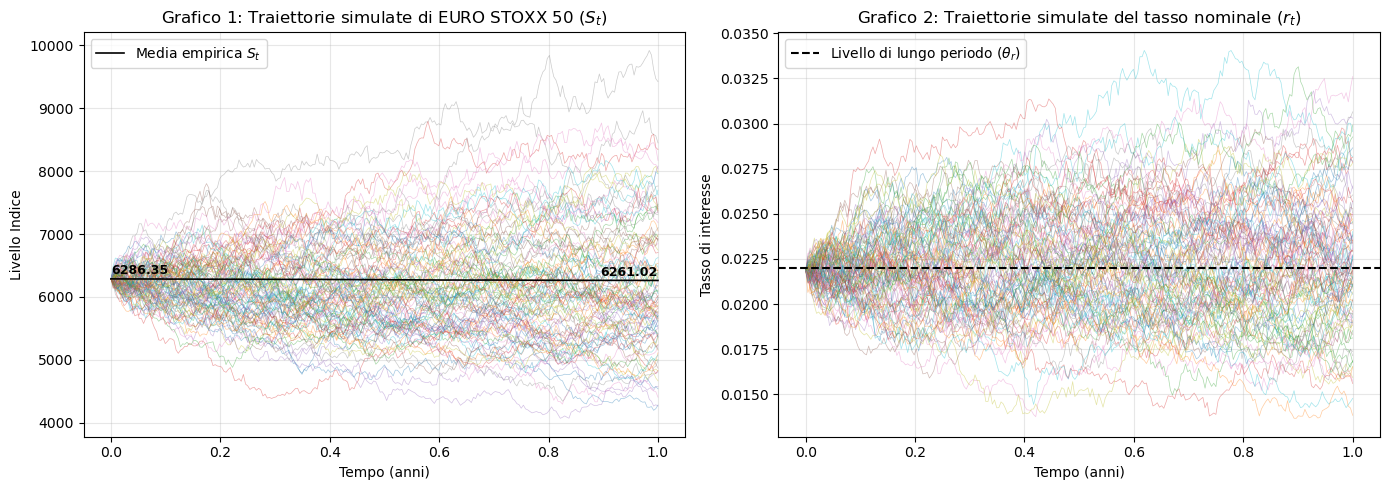

In [12]:
# ====================================================================
# SIMULAZIONE FATTORI (TASSO E INDICE)
# ====================================================================

np.random.seed(seed_value)

Z1 = np.random.standard_normal((M, N))
Z2 = np.random.standard_normal((M, N))

Z_S = Z1
Z_r = rho * Z1 + np.sqrt(1 - rho**2) * Z2

r = np.zeros((M, N + 1))
S = np.zeros((M, N + 1))

r[:, 0] = r_0
S[:, 0] = S_0

for j in range(N):
    r_old = r[:, j]
    S_old = S[:, j]
    
    r_new = r_old + kappa_r * (theta_r - r_old) * dt + \
            sigma_r * np.sqrt(np.maximum(r_old, 0)) * np.sqrt(dt) * Z_r[:, j]
    
    S_new = S_old * np.exp((r_old - q - 0.5 * sigma_S**2) * dt + sigma_S * np.sqrt(dt) * Z_S[:, j])
    
    r[:, j + 1] = r_new
    S[:, j + 1] = S_new

mean_S = np.mean(S, axis=0)

# ====================================================================
# CONTROLLI RICHIESTI
# ====================================================================

print("--- CONTROLLI TAPPA 2 ---")
corr_empirica = np.corrcoef(Z_S.flatten(), Z_r.flatten())[0, 1]
print(f"Controllo 1 - Correlazione empirica shock: {corr_empirica:.4f} (Attesa: {rho})")

s_minimo = np.min(S)
s_positivo = np.all(S > 0)
print(f"Controllo 2 - S_t > 0 per tutte le traiettorie e date: {s_positivo} (Minimo osservato: {s_minimo:.4f})")

num_negativi = np.sum(r < 0)
if num_negativi > 0:
    print(f"Controllo 3 - Valori negativi di r_t rilevati: {num_negativi} occorrenze.")
    print(f"              Valore minimo di r_t osservato: {np.min(r):.6f}")
else:
    print("Controllo 3 - Nessun valore negativo di r_t rilevato dalla discretizzazione.")

print("\nVerifica Media Sottostante:")
print(f"  Valore iniziale (S_0): {S_0:.2f}")
print(f"  Valore medio terminale (S_T): {mean_S[-1]:.2f}")
print("-------------------------\n")

# ====================================================================
# OUTPUT: GRAFICI DELLE TRAIETTORIE
# ====================================================================

num_plot = 100
time_grid = np.linspace(0, T, N + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(time_grid, S[:num_plot, :].T, lw=0.5, alpha=0.4)

# Modifica della linea e inserimento annotazioni
axes[0].plot(time_grid, mean_S, color='black', lw=1.2, label='Media empirica $S_t$')
axes[0].text(time_grid[0], mean_S[0] + 70, f"{mean_S[0]:.2f}", color='black', fontweight='bold', fontsize=9, ha='left')
axes[0].text(time_grid[-1], mean_S[-1] + 70, f"{mean_S[-1]:.2f}", color='black', fontweight='bold', fontsize=9, ha='right')

axes[0].set_title("Grafico 1: Traiettorie simulate di EURO STOXX 50 ($S_t$)")
axes[0].set_xlabel("Tempo (anni)")
axes[0].set_ylabel("Livello Indice")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_grid, r[:num_plot, :].T, lw=0.5, alpha=0.4)
axes[1].set_title("Grafico 2: Traiettorie simulate del tasso nominale ($r_t$)")
axes[1].set_xlabel("Tempo (anni)")
axes[1].set_ylabel("Tasso di interesse")
axes[1].axhline(theta_r, color='black', linestyle='--', label=r'Livello di lungo periodo ($\theta_r$)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Sintesi logica della Tappa 3 (Aggiornata)

- **Criticità individuata:** La distribuzione dei valori attualizzati perde efficacia visiva per i payoff positivi a causa della massa di probabilità sullo zero.
- **Origine della criticità:** L'elevato numero di repliche con valore nullo schiaccia la scala delle frequenze nel Grafico 4.
- **Modifica adottata:** Aggiunta di un grafico specifico per i soli valori attualizzati strettamente positivi.

**Input:**
- Matrici simulate $S$ (EURO STOXX 50) e $r$ (tasso nominale) generate nella Tappa 2.
- Parametri contrattuali e di griglia: strike $K=6300$, numero di intervalli $N=252$, numero di fixing $12$ e ampiezza del passo $\Delta t$.

**Operazioni:**
- Individuazione degli indici delle colonne della matrice $S$ corrispondenti alle date di fixing mensili (passi 21, 42, ..., 252).
- Estrazione dei valori del sottostante in tali date per ogni replica.
- Calcolo della media asiatica aritmetica $A_T^{(k)}$ per ciascuna replica.
- Calcolo del payoff non attualizzato $H_T^{(k)} = \max(A_T^{(k)} - K, 0)$.
- Approssimazione dell'integrale del tasso per ciascuna replica mediante somma di Riemann sinistra, utilizzando i valori $r_{t_0}, \dots, r_{t_{N-1}}$.
- Calcolo del fattore di sconto stocastico $\widehat D^{(k)}(0,T)$.
- Calcolo del valore attualizzato dell'opzione $V^{(k)}$.

**Output:**
- Vettori numerici lunghi $M$ contenenti le realizzazioni di $A_T$, $H_T$, $\widehat D(0,T)$ e $V$.
- **Grafico 3:** Distribuzione simulata di $A_T$, con evidenza dello strike $K$.
- **Grafico 4a:** Distribuzione di tutti i valori attualizzati $V^{(k)}$.
- **Grafico 4b:** Distribuzione dei soli valori attualizzati strettamente positivi ($V^{(k)}>0$).

**Controlli della tappa:**
- **Controllo 4:** Verifica che, per ogni replica, la media $A_T^{(k)}$ sia sempre compresa tra il minimo e il massimo dei valori osservati alle date di fixing.
- **Controllo 5:** Verifica che il payoff $H_T^{(k)}$ sia sempre non negativo e che sia esattamente nullo quando $A_T^{(k)} \le K$.
- **Controllo 6:** Verifica che l'integrale utilizzi correttamente gli $N$ valori antecedenti la scadenza (da $t_0$ a $t_{N-1}$) e che il fattore di sconto sia strettamente positivo.
- **Controllo 7:** Verifica che per ogni replica valga l'identità $V^{(k)} = \widehat D^{(k)}(0,T) H_T^{(k)}$.

**Uso successivo:**
- I vettori $A_T$, $H_T$ e $V$ verranno passati alla Tappa 4 per effettuare l'aggregazione statistica Monte Carlo.

--- CONTROLLI TAPPA 3 ---
Controllo 4 - min(S_tau) <= A_T <= max(S_tau) per ogni replica: True
Controllo 5 - H_T >= 0 per ogni replica: True
              H_T nullo se A_T <= K: True
Controllo 6 - D(0,T) > 0 per ogni replica: True
              L'integrale è stato calcolato su 252 passi (da t_0 a t_251)
Controllo 7 - V^(k) = D^(k)(0,T) * H_T^(k) per ogni replica: True
-------------------------



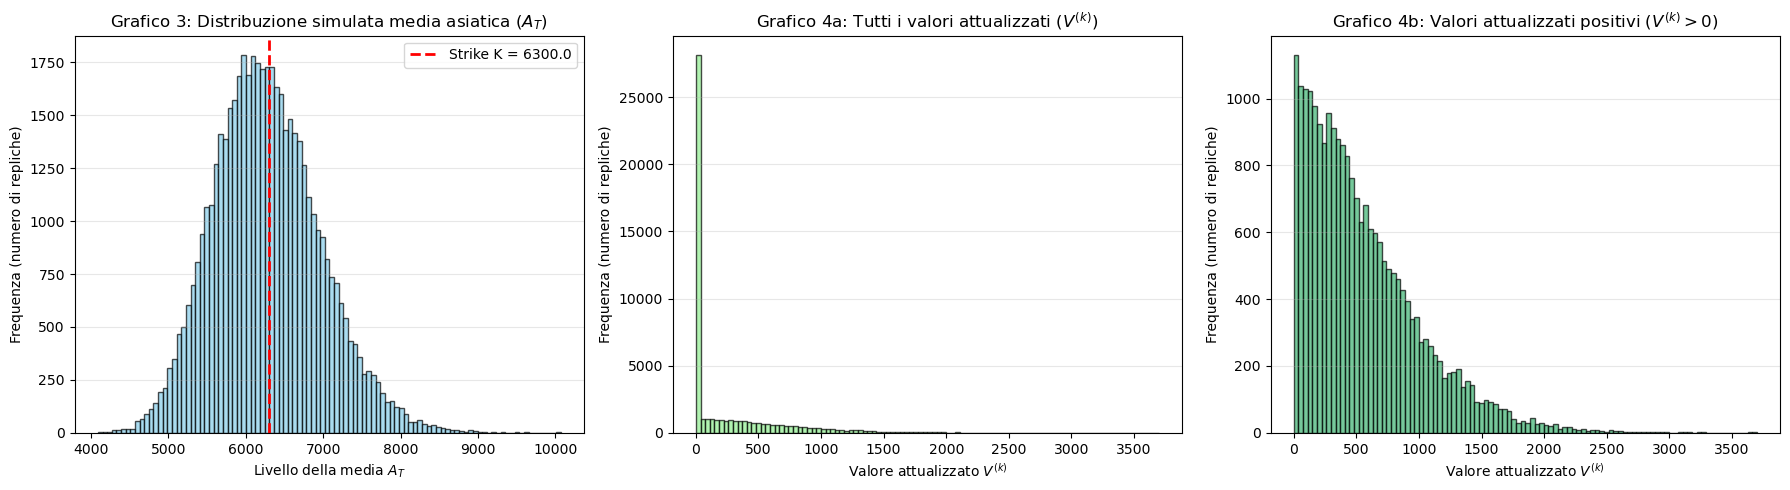

In [13]:
# ====================================================================
# FIXING, PAYOFF E ATTUALIZZAZIONE
# ====================================================================

# 1. Individuazione delle date di fixing
# 12 fixing su 252 passi corrispondono a passi multipli di 21
passo_fixing = int(N / fixing_mensili)
indici_fixing = [h * passo_fixing for h in range(1, fixing_mensili + 1)]

# Estrazione dei valori di S_t ai fixing (matrice M x 12)
S_fixing = S[:, indici_fixing]

# 2. Calcolo Media Asiatica (A_T)
A_T = np.mean(S_fixing, axis=1)

# 3. Calcolo Payoff non attualizzato (H_T)
H_T = np.maximum(A_T - K, 0)

# 4. Attualizzazione
# L'integrale approssimato con Riemann sinistra richiede i valori da t_0 a t_{N-1}
# Estraiamo le prime N colonne della matrice r (indici da 0 a N-1)
integrale_r = np.sum(r[:, :N], axis=1) * dt
D_hat = np.exp(-integrale_r)

# Valore attualizzato della call asiatica (V)
V = D_hat * H_T

# ====================================================================
# CONTROLLI RICHIESTI
# ====================================================================

print("--- CONTROLLI TAPPA 3 ---")

# Controllo 4: Limiti della media asiatica
min_S_fixing = np.min(S_fixing, axis=1)
max_S_fixing = np.max(S_fixing, axis=1)
check_4 = np.all((A_T >= min_S_fixing) & (A_T <= max_S_fixing))
print(f"Controllo 4 - min(S_tau) <= A_T <= max(S_tau) per ogni replica: {check_4}")

# Controllo 5: Proprietà del payoff
check_5a = np.all(H_T >= 0)
check_5b = np.all(H_T[A_T <= K] == 0)
print(f"Controllo 5 - H_T >= 0 per ogni replica: {check_5a}")
print(f"              H_T nullo se A_T <= K: {check_5b}")

# Controllo 6: Costruzione fattore di sconto
check_6a = np.all(D_hat > 0)
num_passi_integrale = r[:, :N].shape[1]
print(f"Controllo 6 - D(0,T) > 0 per ogni replica: {check_6a}")
print(f"              L'integrale è stato calcolato su {num_passi_integrale} passi (da t_0 a t_251)")

# Controllo 7: Formula del valore attualizzato
check_7 = np.allclose(V, D_hat * H_T)
print(f"Controllo 7 - V^(k) = D^(k)(0,T) * H_T^(k) per ogni replica: {check_7}")

print("-------------------------\n")

# ====================================================================
# OUTPUT: GRAFICI DELLE DISTRIBUZIONI
# ====================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafico 3: Distribuzione simulata di A_T
axes[0].hist(A_T, bins=100, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].axvline(K, color='red', linestyle='--', linewidth=2, label=f'Strike K = {K}')
axes[0].set_title("Grafico 3: Distribuzione simulata media asiatica ($A_T$)")
axes[0].set_xlabel("Livello della media $A_T$")
axes[0].set_ylabel("Frequenza (numero di repliche)")
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Grafico 4a: Distribuzione di tutti i valori attualizzati V
axes[1].hist(V, bins=100, color='lightgreen', edgecolor='black', alpha=0.7)
axes[1].set_title("Grafico 4a: Tutti i valori attualizzati ($V^{(k)}$)")
axes[1].set_xlabel("Valore attualizzato $V^{(k)}$")
axes[1].set_ylabel("Frequenza (numero di repliche)")
axes[1].grid(axis='y', alpha=0.3)

# Grafico 4b: Distribuzione dei valori attualizzati strettamente positivi V > 0
V_positivi = V[V > 0]
axes[2].hist(V_positivi, bins=100, color='mediumseagreen', edgecolor='black', alpha=0.7)
axes[2].set_title("Grafico 4b: Valori attualizzati positivi ($V^{(k)} > 0$)")
axes[2].set_xlabel("Valore attualizzato $V^{(k)}$")
axes[2].set_ylabel("Frequenza (numero di repliche)")
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Richiesta dello studente
> Sto lavorando sulla Tappa 4.

### Sintesi logica della Tappa 4

**Input:**
- Vettori delle realizzazioni finali (lunghezza $M$) calcolati nelle tappe precedenti: $S_T$ (valore terminale dell'indice, ovvero ultima colonna della matrice $S$), $r_T$ (valore terminale del tasso, ovvero ultima colonna della matrice $r$), $A_T$ (media asiatica), $H_T$ (payoff non attualizzato) e $V$ (valore attualizzato).
- Costanti: strike $K$, numero di simulazioni $M=50.000$, quantili della normale per l'intervallo di confidenza al $95\%$ ($1,96$).

**Operazioni:**
- Calcolo delle medie campionarie e delle deviazioni standard campionarie per $S_T$, $r_T$ e $A_T$.
- Calcolo della probabilità simulata di esercizio sotto la misura $\mathbb Q$ come frequenza relativa dei casi in cui $A_T > K$.
- Calcolo del valore medio del payoff non attualizzato $H_T$.
- Calcolo del prezzo Monte Carlo $\widehat V_M$ come media campionaria dei valori attualizzati $V^{(k)}$.
- Calcolo dell'errore standard Monte Carlo $SE = \frac{s_V}{\sqrt{M}}$ e del relativo intervallo di confidenza al $95\%$.
- Creazione dei DataFrame Pandas per l'esposizione tabellare.

**Output:**
- **Tabella 2:** Statistiche dei fattori ($S_T$, $r_T$) e della media asiatica ($A_T$).
- **Tabella 3:** Sintesi del payoff, pricing, probabilità e intervallo di confidenza.

**Controlli della tappa:**
- Nessun controllo esplicito di validazione dati richiesto per questa tappa, l'accento è sulla corretta applicazione delle formule statistiche e sulla generazione degli output numerici definitivi per il pricing Monte Carlo basato su $M=50.000$.

**Uso successivo:**
- Le logiche di aggregazione statistica e i risultati di pricing ottenuti in questa tappa costituiscono la base concettuale e il termine di paragone per l'analisi di diagnostica, stabilità e convergenza asintotica che sarà implementata nella Tappa 5.

In [14]:
# ====================================================================
# AGGREGAZIONE STATISTICA E PRICING
# ====================================================================

# 1. Estrazione dei valori terminali
S_T = S[:, -1]
r_T = r[:, -1]

# 2. Calcolo metriche per Tabella 2 (Statistiche di S_T, r_T, A_T)
# Utilizziamo ddof=1 per la deviazione standard campionaria non distorta
stats_S_T = (np.mean(S_T), np.std(S_T, ddof=1))
stats_r_T = (np.mean(r_T), np.std(r_T, ddof=1))
stats_A_T = (np.mean(A_T), np.std(A_T, ddof=1))

# Creazione Tabella 2
dati_tabella_2 = [
    ["Sottostante a scadenza (S_T)", stats_S_T[0], stats_S_T[1]],
    ["Tasso nominale a scadenza (r_T)", stats_r_T[0], stats_r_T[1]],
    ["Media asiatica (A_T)", stats_A_T[0], stats_A_T[1]]
]
tabella_2 = pd.DataFrame(dati_tabella_2, columns=["Variabile", "Media Simulata", "Deviazione Standard Simulata"])

# 3. Calcolo metriche per Tabella 3 (Pricing e Probabilità)
# Probabilità simulata di esercizio sotto Q
prob_esercizio = np.mean(A_T > K)

# Payoff medio
payoff_medio = np.mean(H_T)

# Prezzo Monte Carlo
V_M = np.mean(V)

# Errore Standard Monte Carlo
std_V = np.std(V, ddof=1)
SE_V = std_V / np.sqrt(M)

# Intervallo di confidenza al 95%
CI_lower = V_M - 1.96 * SE_V
CI_upper = V_M + 1.96 * SE_V
CI_str = f"[{CI_lower:.4f}, {CI_upper:.4f}]"

# Creazione Tabella 3
dati_tabella_3 = [
    ["Probabilità simulata di esercizio Q(A_T > K)", f"{prob_esercizio:.4%}"],
    ["Payoff medio non attualizzato (H_T)", f"{payoff_medio:.4f}"],
    ["Prezzo Monte Carlo della call asiatica (V_M)", f"{V_M:.4f}"],
    ["Errore standard Monte Carlo (SE)", f"{SE_V:.6f}"],
    ["Intervallo di confidenza al 95%", CI_str]
]
tabella_3 = pd.DataFrame(dati_tabella_3, columns=["Metrica", "Valore Stimato"])

# ====================================================================
# OUTPUT: TABELLE RISULTATI
# ====================================================================

# Per visualizzare correttamente due DataFrame in Jupyter uno di seguito all'altro, 
# si usa la funzione display() del modulo IPython.display. 
from IPython.display import display

print("OUTPUT RICHIESTO: TABELLA 2")
display(tabella_2.style.set_caption("Tabella 2: Statistiche dei fattori e della media asiatica").hide(axis="index").format({
    "Media Simulata": "{:.6f}",
    "Deviazione Standard Simulata": "{:.6f}"
}))

print("\nOUTPUT RICHIESTO: TABELLA 3")
display(tabella_3.style.set_caption("Tabella 3: Sintesi del payoff e del pricing").hide(axis="index"))

OUTPUT RICHIESTO: TABELLA 2


Variabile,Media Simulata,Deviazione Standard Simulata
Sottostante a scadenza (S_T),6261.021455,1124.856891
Tasso nominale a scadenza (r_T),0.021952,0.003587
Media asiatica (A_T),6271.811696,689.134865



OUTPUT RICHIESTO: TABELLA 3


Metrica,Valore Stimato
Probabilità simulata di esercizio Q(A_T > K),45.9380%
Payoff medio non attualizzato (H_T),260.6226
Prezzo Monte Carlo della call asiatica (V_M),255.1539
Errore standard Monte Carlo (SE),1.844978
Intervallo di confidenza al 95%,"[251.5377, 258.7700]"


### Richiesta dello studente
> Sto lavorando sulla Tappa 5.

### Sintesi logica della Tappa 5

**Input:**
- Parametri di base scalari ($S_0, r_0, K, T, \dots$) e seed pseudocasuale (`seed_value`) inizializzati nella Tappa 1.
- Il vettore delle simulazioni finali $V$, l'errore standard `SE_V` e il prezzo `V_M` ottenuti nella Tappa 4 (necessari per il grafico di convergenza e i test di riproducibilità).
- L'array delle numerosità Monte Carlo richieste $M = [1.000, 5.000, 10.000, 50.000]$ e l'impostazione per una griglia temporale raddoppiata ($N_{fine} = 504$).

**Operazioni:**
- Definizione di una funzione Python che incapsula coerentemente le Tappe 2 e 3, al fine di poter ripetere in modo pulito l'intera simulazione al variare dei parametri.
- Esecuzione iterativa della funzione per ciascun valore di $M$ specificato.
- Esecuzione della funzione con la griglia temporale più fine (passo $\Delta t / 2$).
- Costruzione della Tabella 4 e aggregazione dei dati cumulativi per il grafico di convergenza.

**Output:**
- **Tabella 4:** Diagnostica Monte Carlo, che riporta prezzo stimato ed errore standard al variare di $M$.
- **Grafico 5:** Curva di convergenza della stima Monte Carlo ($\widehat V_m$) al crescere del numero di repliche, con relative fasce di confidenza al $95\%$.

**Controlli della tappa:**
- **Controllo 8:** Verifica dell'ipotesi asintotica, documentando che l'errore standard si riduce a un tasso compatibile con $O(M^{-1/2})$ (il prodotto $SE \times \sqrt{M}$ deve risultare approssimativamente costante).
- **Controllo 9:** Verifica di stabilità, confrontando il prezzo ottenuto con $N=252$ e il prezzo con $N=504$.
- **Controllo 10:** Conferma della riproducibilità, accertando che l'esecuzione della funzione per $M=50.000$ restituisca esattamente l'output originario della Tappa 4, a parità di seed.

**Uso successivo:**
- Termine della comput

--- CONTROLLI TAPPA 5 ---
Controllo 8 - Decadimento Errore Standard in O(M^{-1/2}):
  M =  1000 -> SE = 13.004172 | Costante asintotica [SE * sqrt(M)] = 411.2280
  M =  5000 -> SE = 5.954132 | Costante asintotica [SE * sqrt(M)] = 421.0207
  M = 10000 -> SE = 4.213651 | Costante asintotica [SE * sqrt(M)] = 421.3651
  M = 50000 -> SE = 1.844978 | Costante asintotica [SE * sqrt(M)] = 412.5495
  (Il prodotto approssimativamente costante dimostra il decadimento con radice di M)

Controllo 9 - Stabilità griglia temporale:
  Prezzo con N=252: 255.1539
  Prezzo con N=504: 255.3560
  Differenza assoluta: 0.2021

Controllo 10 - Riproducibilità risultati:
  Prezzo M=50.000 (ricavato ora):       255.1539
  Prezzo M=50.000 (Tappa 4 originale):  255.1539
  Risultati coincidenti tramite seed=12345: True
-------------------------

OUTPUT RICHIESTO: TABELLA 4


Repliche (M),Prezzo Stimato,Errore Standard (SE),SE * radice(M) (Proxy Dev. Std.)
1000,256.9303,13.004172,411.2280
5000,265.1401,5.954132,421.0207
10000,260.8794,4.213651,421.3651
50000,255.1539,1.844978,412.5495


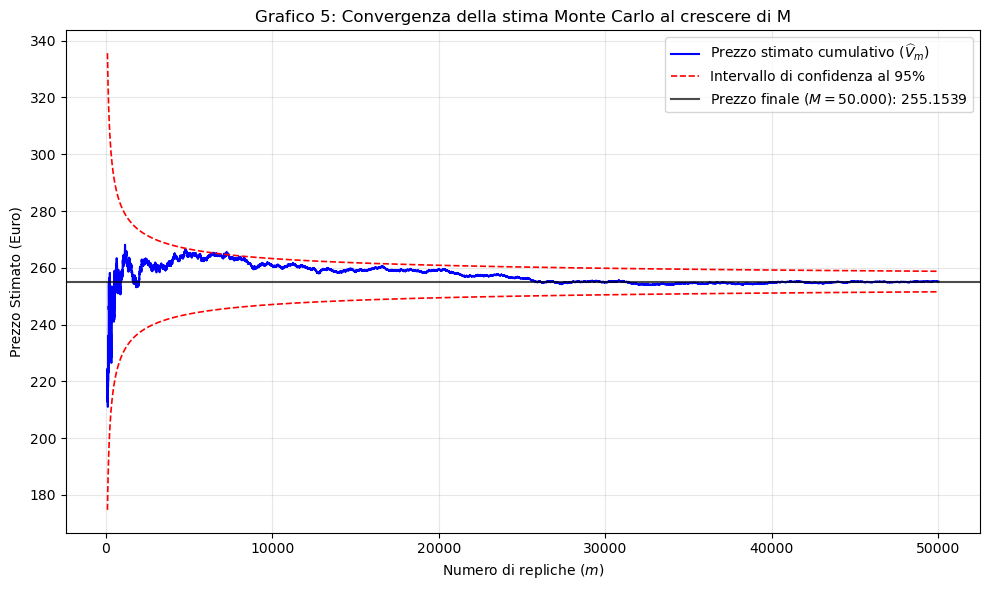

In [15]:
# ====================================================================
# DIAGNOSTICA E STABILITÀ
# ====================================================================

# Funzione incapsulata per rigenerare simulazioni e pricing
def esegui_simulazione_e_pricing(M_sim, N_sim, seed_val):
    # Fissaggio del seed per riproducibilità
    np.random.seed(seed_val)
    
    dt_sim = T / N_sim
    
    # 1. Shock
    Z1 = np.random.standard_normal((M_sim, N_sim))
    Z2 = np.random.standard_normal((M_sim, N_sim))
    Z_S = Z1
    Z_r = rho * Z1 + np.sqrt(1 - rho**2) * Z2
    
    # 2. Inizializzazione
    r_sim = np.zeros((M_sim, N_sim + 1))
    S_sim = np.zeros((M_sim, N_sim + 1))
    r_sim[:, 0] = r_0
    S_sim[:, 0] = S_0
    
    # 3. Loop temporale
    for j in range(N_sim):
        r_old = r_sim[:, j]
        S_old = S_sim[:, j]
        
        r_new = r_old + kappa_r * (theta_r - r_old) * dt_sim + \
                sigma_r * np.sqrt(np.maximum(r_old, 0)) * np.sqrt(dt_sim) * Z_r[:, j]
        
        S_new = S_old * np.exp((r_old - q - 0.5 * sigma_S**2) * dt_sim + sigma_S * np.sqrt(dt_sim) * Z_S[:, j])
        
        r_sim[:, j + 1] = r_new
        S_sim[:, j + 1] = S_new
        
    # 4. Fixing (adattamento dinamico alla griglia)
    passo_fix = int(N_sim / fixing_mensili)
    idx_fix = [h * passo_fix for h in range(1, fixing_mensili + 1)]
    
    S_fix = S_sim[:, idx_fix]
    A_T_sim = np.mean(S_fix, axis=1)
    H_T_sim = np.maximum(A_T_sim - K, 0)
    
    # 5. Attualizzazione
    integrale = np.sum(r_sim[:, :N_sim], axis=1) * dt_sim
    D_hat_sim = np.exp(-integrale)
    
    V_sim = D_hat_sim * H_T_sim
    
    prezzo_m = np.mean(V_sim)
    std_m = np.std(V_sim, ddof=1)
    se_m = std_m / np.sqrt(M_sim)
    
    return prezzo_m, se_m, std_m

# Analisi su diverse numerosità Monte Carlo
M_list = [1000, 5000, 10000, 50000]
risultati_diagnostica = []

for m_val in M_list:
    p_m, se_m, std_m = esegui_simulazione_e_pricing(m_val, N, seed_value)
    # Conserviamo anche la stima asintotica della deviazione standard per il Controllo 8
    proxy_costante = se_m * np.sqrt(m_val)
    risultati_diagnostica.append([m_val, p_m, se_m, proxy_costante])

# Creazione Tabella 4
tabella_4 = pd.DataFrame(risultati_diagnostica, columns=[
    "Repliche (M)", 
    "Prezzo Stimato", 
    "Errore Standard (SE)", 
    "SE * radice(M) (Proxy Dev. Std.)"
])

# Analisi di stabilità su griglia temporale raddoppiata (N=504, ovvero dt dimezzato)
N_fine = 504
prezzo_Nfine, se_Nfine, _ = esegui_simulazione_e_pricing(M, N_fine, seed_value)

# ====================================================================
# CONTROLLI RICHIESTI
# ====================================================================

print("--- CONTROLLI TAPPA 5 ---")

# Controllo 8: Decadimento O(M^{-1/2})
print("Controllo 8 - Decadimento Errore Standard in O(M^{-1/2}):")
for row in risultati_diagnostica:
    print(f"  M = {row[0]:5d} -> SE = {row[2]:.6f} | Costante asintotica [SE * sqrt(M)] = {row[3]:.4f}")
print("  (Il prodotto approssimativamente costante dimostra il decadimento con radice di M)")

# Controllo 9: Stabilità temporale
prezzo_riferimento = risultati_diagnostica[-1][1] # Prezzo per M=50.000, N=252
diff_assoluta = abs(prezzo_riferimento - prezzo_Nfine)
print(f"\nControllo 9 - Stabilità griglia temporale:")
print(f"  Prezzo con N=252: {prezzo_riferimento:.4f}")
print(f"  Prezzo con N=504: {prezzo_Nfine:.4f}")
print(f"  Differenza assoluta: {diff_assoluta:.4f}")

# Controllo 10: Riproducibilità
print(f"\nControllo 10 - Riproducibilità risultati:")
print(f"  Prezzo M=50.000 (ricavato ora):       {prezzo_riferimento:.4f}")
print(f"  Prezzo M=50.000 (Tappa 4 originale):  {V_M:.4f}")
check_repro = np.isclose(prezzo_riferimento, V_M)
print(f"  Risultati coincidenti tramite seed={seed_value}: {check_repro}")

print("-------------------------\n")

# ====================================================================
# OUTPUT: TABELLA E GRAFICO
# ====================================================================

from IPython.display import display

print("OUTPUT RICHIESTO: TABELLA 4")
display(tabella_4.style.set_caption("Tabella 4: Diagnostica Monte Carlo").hide(axis="index").format({
    "Prezzo Stimato": "{:.4f}",
    "Errore Standard (SE)": "{:.6f}",
    "SE * radice(M) (Proxy Dev. Std.)": "{:.4f}"
}))

# Grafico 5: Convergenza della stima Monte Carlo
# Utilizziamo le medie progressive del vettore V già calcolato in Tappa 3/4 per tracciare la curva completa in modo efficiente
M_grid = np.arange(1, M + 1)
running_mean = np.cumsum(V) / M_grid
running_SE = std_V / np.sqrt(M_grid)

# Tronchiamo i primi 100 valori per evitare che l'altissima volatilità iniziale distorca l'asse Y
start_idx = 100

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(M_grid[start_idx:], running_mean[start_idx:], color='blue', lw=1.5, label='Prezzo stimato cumulativo ($\widehat{V}_m$)')
ax.plot(M_grid[start_idx:], V_M + 1.96 * running_SE[start_idx:], color='red', linestyle='--', lw=1.2, label='Intervallo di confidenza al 95%')
ax.plot(M_grid[start_idx:], V_M - 1.96 * running_SE[start_idx:], color='red', linestyle='--', lw=1.2)
ax.axhline(V_M, color='black', linestyle='-', lw=1.5, alpha=0.7, label=f'Prezzo finale ($M=50.000$): {V_M:.4f}')

ax.set_title("Grafico 5: Convergenza della stima Monte Carlo al crescere di M")
ax.set_xlabel("Numero di repliche ($m$)")
ax.set_ylabel("Prezzo Stimato (Euro)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

L'implementazione del Caso Takehome 7 ha portato a ottimi risultati. L'interazione con l'intelligenza ha funzionato molto bene, ha mostrato dei limiti solo nella parte di rappresentazione grafica dei concetti utili alla valutazione del caso. Il risultato è stato raggiunto e tutti i controlli sono coerenti con quanto richiesto dalla scheda caso.